# Guía de Práctica N° 12: Evaluación de clasificadores y selección de métricas
**Curso:** Análisis de Datos (SIS323) · 2026-II · **Datos:** `clientes_isp.csv`  
**Integrantes:** Mamani Zapana Edward, Mamani Panca Roger Golber, Gutierrez Arratia Kevin Diego

## Paso 1: Matriz de confusión de cada modelo

Clientes en prueba: 225 | bajas reales: 51


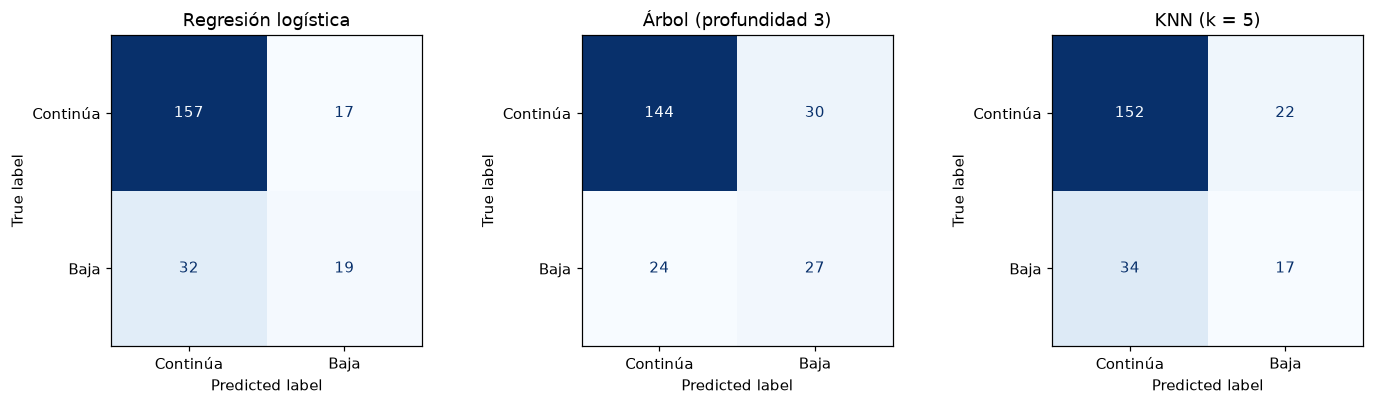

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import ConfusionMatrixDisplay

isp = pd.read_csv("clientes_isp.csv")
X = pd.get_dummies(isp.drop(columns=["cliente_id", "baja"]), drop_first=True, dtype=int)
y = isp["baja"]
X_ent, X_pru, y_ent, y_pru = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

modelos = {
    "Regresión logística": make_pipeline(StandardScaler(), LogisticRegression()),
    "Árbol (profundidad 3)": DecisionTreeClassifier(max_depth=3, random_state=42),
    "KNN (k = 5)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
}
for m in modelos.values():
    m.fit(X_ent, y_ent)

print("Clientes en prueba:", len(y_pru), "| bajas reales:", int(y_pru.sum()))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (nombre, m) in zip(axes, modelos.items()):
    ConfusionMatrixDisplay.from_estimator(
        m, X_pru, y_pru, display_labels=["Continúa", "Baja"], cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

## Paso 2: Precisión, recall y F1

In [2]:
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score

filas = []
for nombre, m in modelos.items():
    pred = m.predict(X_pru)
    vn, fp, fn, vp = confusion_matrix(y_pru, pred).ravel()
    filas.append({
        "modelo": nombre, "VP": vp, "FP": fp, "FN": fn, "VN": vn,
        "exactitud": accuracy_score(y_pru, pred),
        "precisión": precision_score(y_pru, pred),
        "recall": recall_score(y_pru, pred),
        "F1": f1_score(y_pru, pred),
    })

tabla = pd.DataFrame(filas).set_index("modelo").round(3)
print(tabla.to_string())

# Comprobación a mano (Regresión logística)
print("\nComprobación a mano (Regresión logística):")
print(f"Precisión = 19 / (19 + 17) = {19/36:.3f}")
print(f"Recall    = 19 / (19 + 32) = {19/51:.3f}")

                       VP  FP  FN   VN  exactitud  precisión  recall     F1
modelo                                                                     
Regresión logística    19  17  32  157      0.782      0.528   0.373  0.437
Árbol (profundidad 3)  27  30  24  144      0.760      0.474   0.529  0.500
KNN (k = 5)            17  22  34  152      0.751      0.436   0.333  0.378

Comprobación a mano (Regresión logística):
Precisión = 19 / (19 + 17) = 0.528
Recall    = 19 / (19 + 32) = 0.373


## Paso 3: Costo de cada error y métrica principal
- **Falso positivo (FP):** llamada innecesaria a un cliente que continuaría (costo bajo).
- **Falso negativo (FN):** no detectar una baja y perder al cliente (costo alto).
- **Métrica principal:** **Recall**, porque el error más costoso es el falso negativo.

## Paso 4: Ajustar el umbral de decisión

In [3]:
prob = modelos["Regresión logística"].predict_proba(X_pru)[:, 1]
for umbral in (0.5, 0.4, 0.3, 0.2):
    pred = (prob >= umbral).astype(int)
    print(
        f"Umbral {umbral:.1f}: precisión = {precision_score(y_pru, pred):.2f}  "
        f"recall = {recall_score(y_pru, pred):.2f}  F1 = {f1_score(y_pru, pred):.2f}  "
        f"clientes a llamar = {pred.sum()}"
    )

Umbral 0.5: precisión = 0.53  recall = 0.37  F1 = 0.44  clientes a llamar = 36
Umbral 0.4: precisión = 0.56  recall = 0.53  F1 = 0.55  clientes a llamar = 48
Umbral 0.3: precisión = 0.46  recall = 0.61  F1 = 0.53  clientes a llamar = 67
Umbral 0.2: precisión = 0.40  recall = 0.75  F1 = 0.52  clientes a llamar = 94


## Paso 5: Modelo final elegido
- **Recomendación:** **Regresión logística con umbral `0.3`**.
- **Justificación:** Alcanza **recall = 0.61** (31 de 51 bajas), superando al árbol (`0.53`) y a KNN (`0.33`), con **67 llamadas** manejables para un equipo regional (con `0.2` serían 94 llamadas).

## Paso 6: Decisiones de modelado (LC2)
- **División:** 75 % entrenamiento / 25 % prueba, `random_state=42`, `stratify=y`.
- **Preprocesamiento:** `get_dummies(drop_first=True)` y `StandardScaler` en pipeline para Regresión logística y KNN.
- **Evaluación:** Métrica principal **Recall** y umbral de negocio **`0.3`** en prueba.